In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load JobMatch dataset
job_df = pd.read_csv("../data/processed/job_dataset_normalized.csv")

# Display dataset dimensions
print("JOBMATCH DATASET")
print("=" * 50)
print("Rows:", job_df.shape[0])
print("Columns:", job_df.shape[1])

# Display first five records
display(job_df.head())

JOBMATCH DATASET
Rows: 6000
Columns: 16


,Highest_Qualification,Specialization,Experience_Years,Technical_Skills,Soft_Skills,Certifications,Fields_of_Interest,Employment_Type_Interest,Expected_Salary_INR_Annual,Resume_Summary,Recommended_Job,Salary_At_Observed_Cap,Technical_Skills_Parsed,Soft_Skills_Parsed,Technical_Skill_Count,Soft_Skill_Count
0,BCA,Business Administration,10,Talent Acquisition; HRIS; Excel; Communication...,Creativity; Leadership; Decision Making; Time ...,Google Data Analytics,Human Resources,Contract,500000,Candidate with 10 years of experience interest...,HR Manager / Talent Acquisition Lead,True,Talent Acquisition; HRIS; Excel; Communication...,Creativity; Leadership; Decision Making; Time ...,5,4
1,B.Com,Information Technology,0,Python; Power BI; Tableau; NumPy,Problem Solving; Teamwork; Adaptability; Colla...,Azure Fundamentals,Data Analytics,Freelance,358000,Entry-level candidate interested in Data Analy...,Junior Data Analyst,False,Python; Power BI; Tableau; NumPy,Problem Solving; Teamwork; Adaptability; Colla...,4,4
2,B.Sc,Information Technology,0,Selenium; Jira; Manual Testing; SQL; Python,Critical Thinking; Adaptability,Microsoft Power BI Data Analyst,Quality Assurance,Part-time,302000,Entry-level candidate interested in Quality As...,Junior QA / Test Engineer,False,Selenium; Jira; Manual Testing; SQL; Python,Critical Thinking; Adaptability,5,2
3,B.Sc,Cloud Computing,1,Power BI; Process Mapping; Documentation; Exce...,Problem Solving; Creativity,Google UX Design,Business Analysis,Internship,375000,Candidate with 1 years of experience intereste...,Junior Business Analyst,False,Power BI; Process Mapping; Documentation; Exce...,Problem Solving; Creativity,5,2
4,B.Com,Statistics,0,CI/CD; Kubernetes; Git; AWS,Critical Thinking; Collaboration,Digital Marketing Certificate,Cloud Computing,Full-time,268000,Entry-level candidate interested in Cloud Comp...,Junior Cloud Engineer,False,CI/CD; Kubernetes; Git; AWS,Critical Thinking; Collaboration,4,2


In [2]:
# Dataset structure
print("DATASET INFORMATION")
print("=" * 60)

job_df.info()

print("\nCOLUMN NAMES")
print("=" * 60)

for column in job_df.columns:
    print(column)

print("\nDATA TYPES")
print("=" * 60)

display(job_df.dtypes)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Highest_Qualification       6000 non-null   str  
 1   Specialization              6000 non-null   str  
 2   Experience_Years            6000 non-null   int64
 3   Technical_Skills            6000 non-null   str  
 4   Soft_Skills                 6000 non-null   str  
 5   Certifications              6000 non-null   str  
 6   Fields_of_Interest          6000 non-null   str  
 7   Employment_Type_Interest    6000 non-null   str  
 8   Expected_Salary_INR_Annual  6000 non-null   int64
 9   Resume_Summary              6000 non-null   str  
 10  Recommended_Job             6000 non-null   str  
 11  Salary_At_Observed_Cap      6000 non-null   bool 
 12  Technical_Skills_Parsed     6000 non-null   str  
 13  Soft_Skills_Parsed          6000 non-null   str  
 14 

Highest_Qualification           str
Specialization                  str
Experience_Years              int64
Technical_Skills                str
Soft_Skills                     str
Certifications                  str
Fields_of_Interest              str
Employment_Type_Interest        str
Expected_Salary_INR_Annual    int64
Resume_Summary                  str
Recommended_Job                 str
Salary_At_Observed_Cap         bool
Technical_Skills_Parsed         str
Soft_Skills_Parsed              str
Technical_Skill_Count         int64
Soft_Skill_Count              int64
dtype: object

In [3]:
# Missing value analysis
print("MISSING VALUE ANALYSIS")
print("=" * 60)

missing = job_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(job_df)) * 100
})

display(missing_summary)

# Duplicate analysis
print("\nDUPLICATE ANALYSIS")
print("=" * 60)

print("Full duplicate rows:", job_df.duplicated().sum())

# Blank string analysis
print("\nBLANK STRING ANALYSIS")
print("=" * 60)

for column in job_df.select_dtypes(include="str").columns:
    blank_count = job_df[column].str.strip().eq("").sum()
    if blank_count > 0:
        print(column, ":", blank_count)

print("\nDATA QUALITY CHECK COMPLETED")


MISSING VALUE ANALYSIS


,Missing_Count,Missing_Percentage
Highest_Qualification,0,0.0
Specialization,0,0.0
Experience_Years,0,0.0
Technical_Skills,0,0.0
Soft_Skills,0,0.0
Certifications,0,0.0
Fields_of_Interest,0,0.0
Employment_Type_Interest,0,0.0
Expected_Salary_INR_Annual,0,0.0
Resume_Summary,0,0.0



DUPLICATE ANALYSIS
Full duplicate rows: 0

BLANK STRING ANALYSIS

DATA QUALITY CHECK COMPLETED


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

job_df = pd.read_csv(
    project_root / "data" / "processed" / "job_dataset_normalized.csv"
)

print("Job dataset loaded:", job_df.shape)

Job dataset loaded: (6000, 16)


Top 20 Floating JOB DISTRIBUTION


,Record_Count
Floating_Job,
Web Developer,510
Junior Financial Analyst,260
Digital Marketing Associate,260
Junior QA / Test Engineer,255
Junior Machine Learning Associate,246
HR / Recruitment Associate,246
Junior Business Analyst,245
Junior Data Analyst,243
Junior UI/UX Designer,239



Total unique job categories: 34


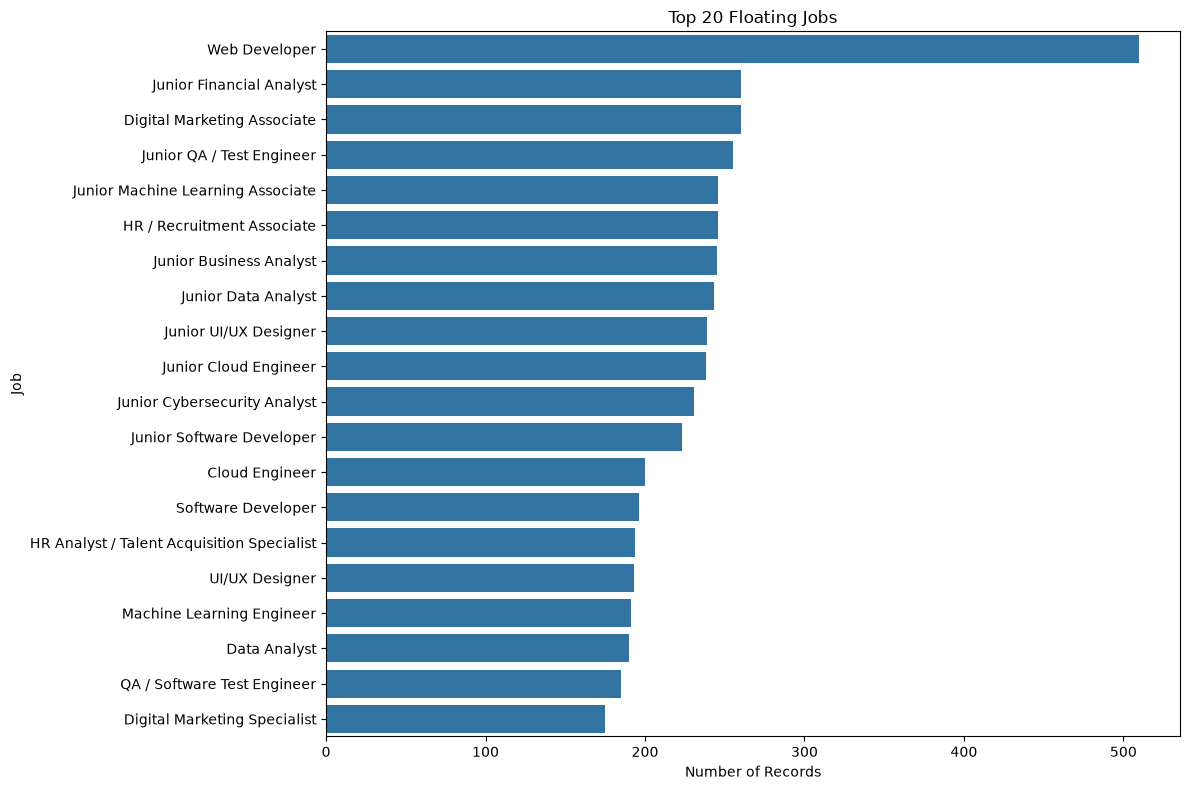

In [14]:
# Recommended job distribution

print("Top 20 Floating JOB DISTRIBUTION")
print("=" * 60)

job_counts = job_df["Recommended_Job"].value_counts().rename_axis("Floating_Job")

display(job_counts.to_frame(name="Record_Count"))

print("\nTotal unique job categories:", job_df["Recommended_Job"].nunique())

# Visualize top 20 jobs
plt.figure(figsize=(12, 8))

sns.barplot(
    x=job_counts.head(20).values,
    y=job_counts.head(20).index
)

plt.title("Top 20 Floating Jobs")
plt.xlabel("Number of Records")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

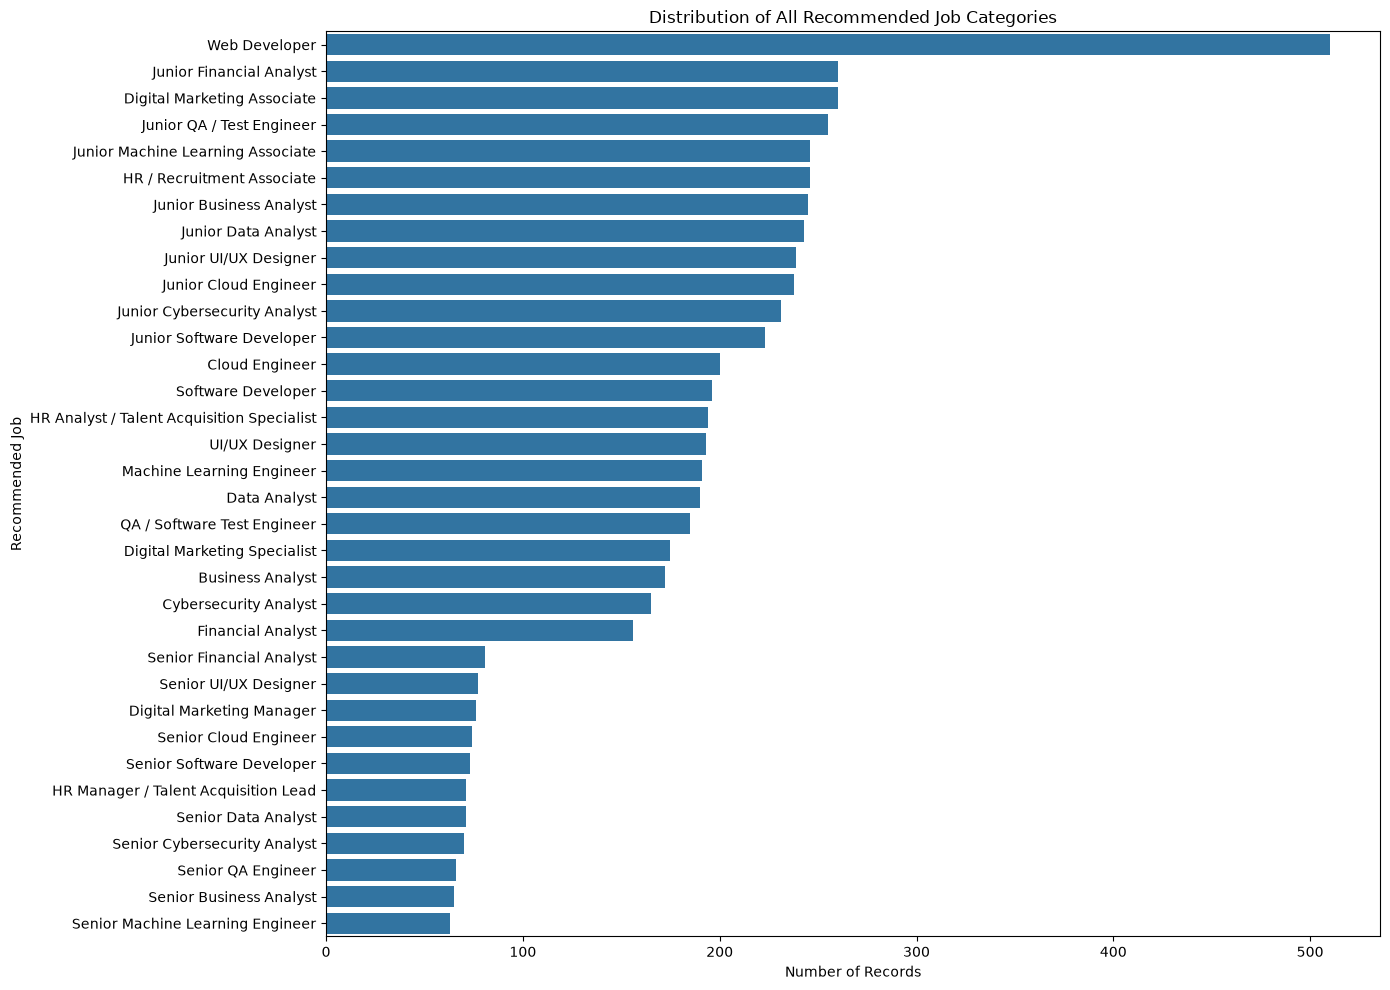

In [5]:
# Complete job distribution visualization

plt.figure(figsize=(14, 10))

sns.countplot(
    data=job_df,
    y="Recommended_Job",
    order=job_df["Recommended_Job"].value_counts().index
)

plt.title("Distribution of All Recommended Job Categories")
plt.xlabel("Number of Records")
plt.ylabel("Recommended Job")
plt.tight_layout()
plt.show()

EXPERIENCE DISTRIBUTION


,Record_Count
Experience_Years,
0,2028
1,912
2,713
3,606
4,442
5,425
6,297
7,182
8,202


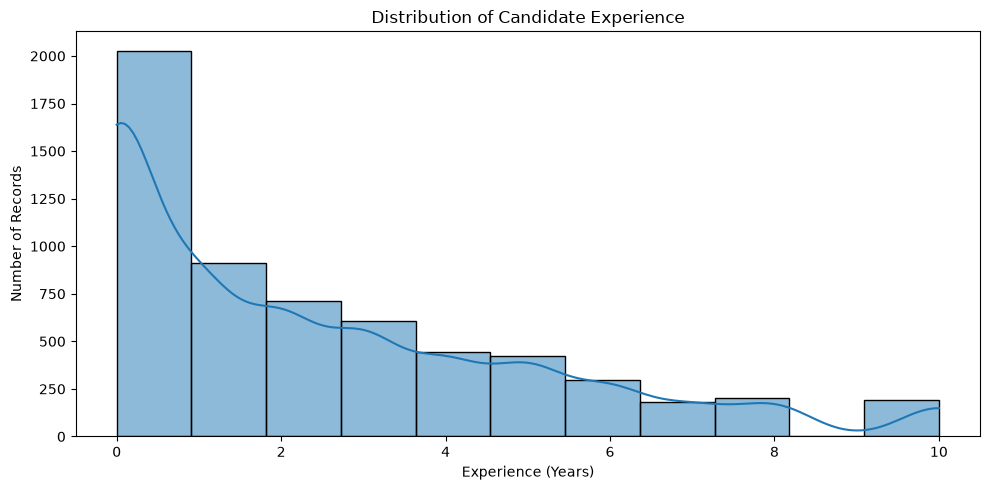

In [6]:
# Experience distribution

print("EXPERIENCE DISTRIBUTION")
print("=" * 60)

display(
    job_df["Experience_Years"]
    .value_counts()
    .sort_index()
    .to_frame(name="Record_Count")
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=job_df,
    x="Experience_Years",
    bins=11,
    kde=True
)

plt.title("Distribution of Candidate Experience")
plt.xlabel("Experience (Years)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

HIGHEST QUALIFICATION DISTRIBUTION


,Record_Count
Highest_Qualification,
M.Sc,581
BE,562
Diploma,556
B.Tech,551
BA,545
B.Sc,544
MBA,543
BCA,541
MCA,536



Total qualifications: 11


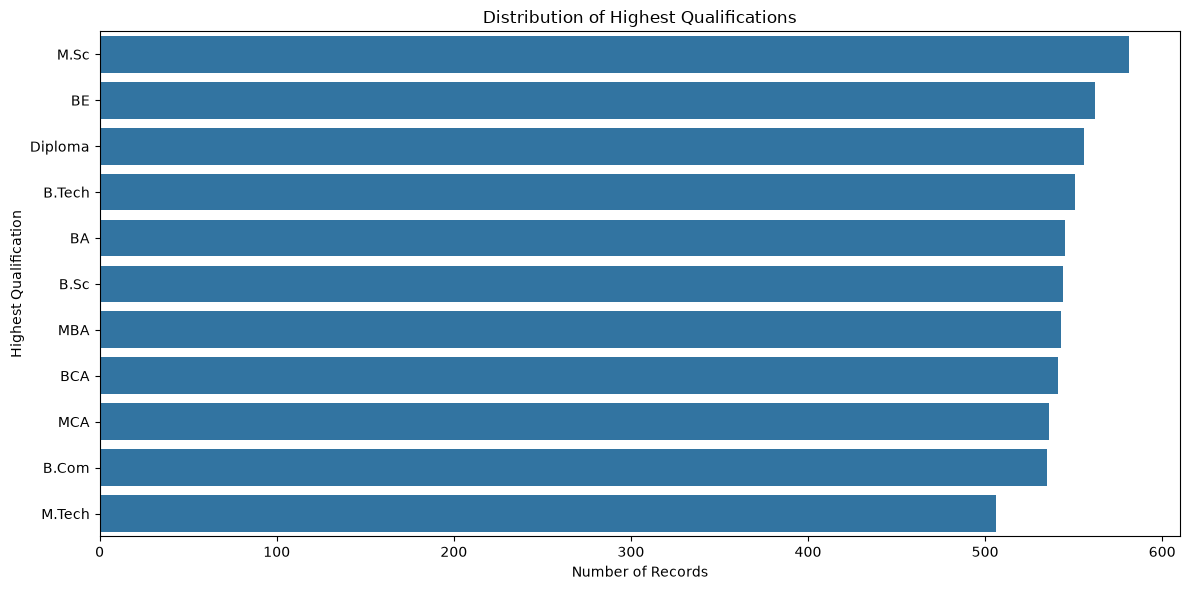

In [7]:
# Education qualification distribution

print("HIGHEST QUALIFICATION DISTRIBUTION")
print("=" * 60)

qualification_counts = job_df["Highest_Qualification"].value_counts()

display(
    qualification_counts.to_frame(name="Record_Count")
)

print("\nTotal qualifications:",
      job_df["Highest_Qualification"].nunique())

plt.figure(figsize=(12, 6))

sns.countplot(
    data=job_df,
    y="Highest_Qualification",
    order=qualification_counts.index
)

plt.title("Distribution of Highest Qualifications")
plt.xlabel("Number of Records")
plt.ylabel("Highest Qualification")
plt.tight_layout()
plt.show()

SPECIALIZATION DISTRIBUTION


,Record_Count
Specialization,
Design,433
Marketing,421
Business Administration,418
Cloud Computing,415
Electronics,415
Cybersecurity,407
Computer Science,406
Statistics,405
Mathematics,400



Total unique specializations: 15


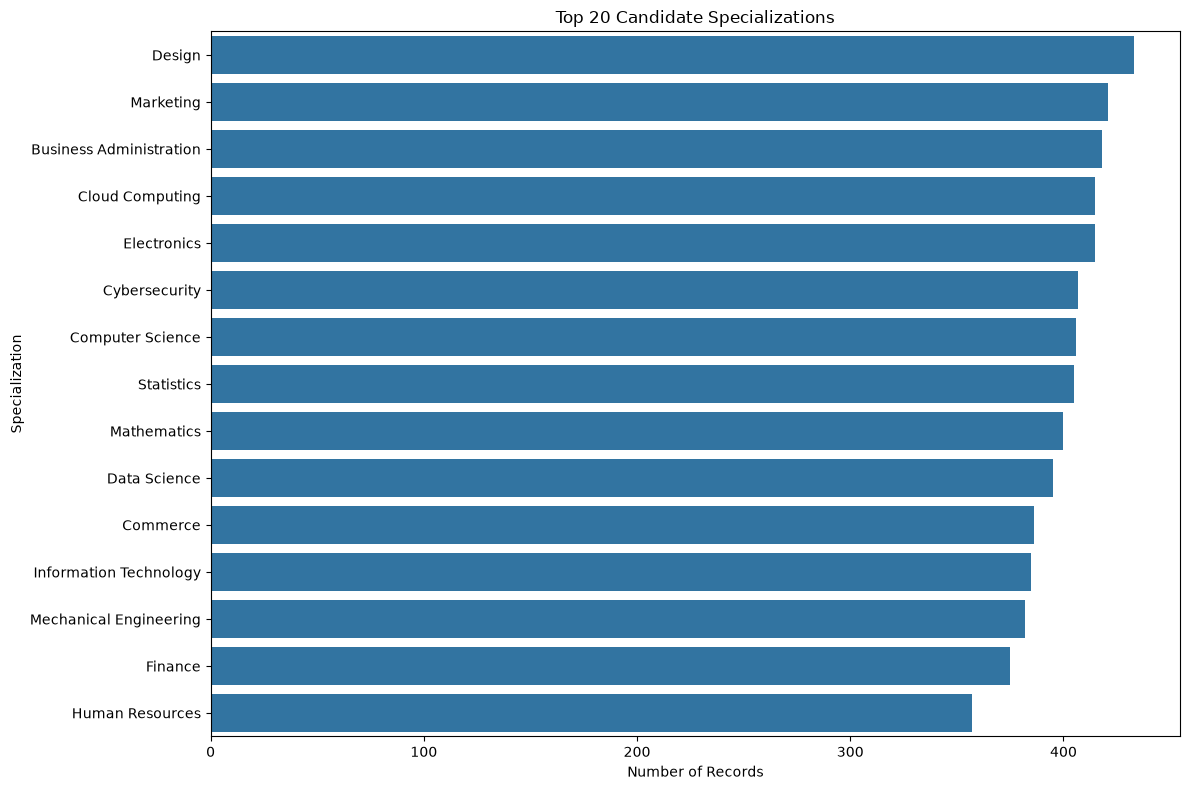

In [8]:
# Specialization distribution

print("SPECIALIZATION DISTRIBUTION")
print("=" * 60)

specialization_counts = job_df["Specialization"].value_counts()

display(
    specialization_counts.to_frame(name="Record_Count")
)

print("\nTotal unique specializations:",
      job_df["Specialization"].nunique())

# Visualize top 20 specializations
plt.figure(figsize=(12, 8))

sns.countplot(
    data=job_df,
    y="Specialization",
    order=specialization_counts.head(20).index
)

plt.title("Top 20 Candidate Specializations")
plt.xlabel("Number of Records")
plt.ylabel("Specialization")
plt.tight_layout()
plt.show()


In [9]:
# Technical skills inspection

print("TECHNICAL SKILLS ANALYSIS")
print("=" * 60)

print("Data type:", job_df["Technical_Skills_Parsed"].dtype)

print("\nFirst 10 technical skill records:")
display(
    job_df[["Technical_Skills", "Technical_Skills_Parsed"]].head(10)
)

print("\nUnique technical skill combinations:",
      job_df["Technical_Skills_Parsed"].nunique())

TECHNICAL SKILLS ANALYSIS
Data type: str

First 10 technical skill records:


,Technical_Skills,Technical_Skills_Parsed
0,Talent Acquisition; HRIS; Excel; Communication...,Talent Acquisition; HRIS; Excel; Communication...
1,Python; Power BI; Tableau; NumPy,Python; Power BI; Tableau; NumPy
2,Selenium; Jira; Manual Testing; SQL; Python,Selenium; Jira; Manual Testing; SQL; Python
3,Power BI; Process Mapping; Documentation; Exce...,Power BI; Process Mapping; Documentation; Exce...
4,CI/CD; Kubernetes; Git; AWS,CI/CD; Kubernetes; Git; AWS
5,NLP; Machine Learning; NumPy; Statistics; PyTo...,NLP; Machine Learning; NumPy; Statistics; PyTo...
6,SQL; Financial Modeling; Power BI; Excel; Acco...,SQL; Financial Modeling; Power BI; Excel; Acco...
7,SQL; Budgeting; Financial Analysis; Excel; Pow...,SQL; Budgeting; Financial Analysis; Excel; Pow...
8,Networking; Cloud Security; Linux; Python,Networking; Cloud Security; Linux; Python
9,Budgeting; Financial Analysis; Accounting; Fin...,Budgeting; Financial Analysis; Accounting; Fin...



Unique technical skill combinations: 5498


TOP 20 TECHNICAL SKILLS


,Technical_Skill,Record_Count
0,Python,1759
1,Excel,1739
2,SQL,1596
3,Power BI,995
4,Git,884
5,Networking,638
6,Linux,598
7,REST APIs,573
8,Django,544
9,Pandas,542



Total unique individual technical skills: 66


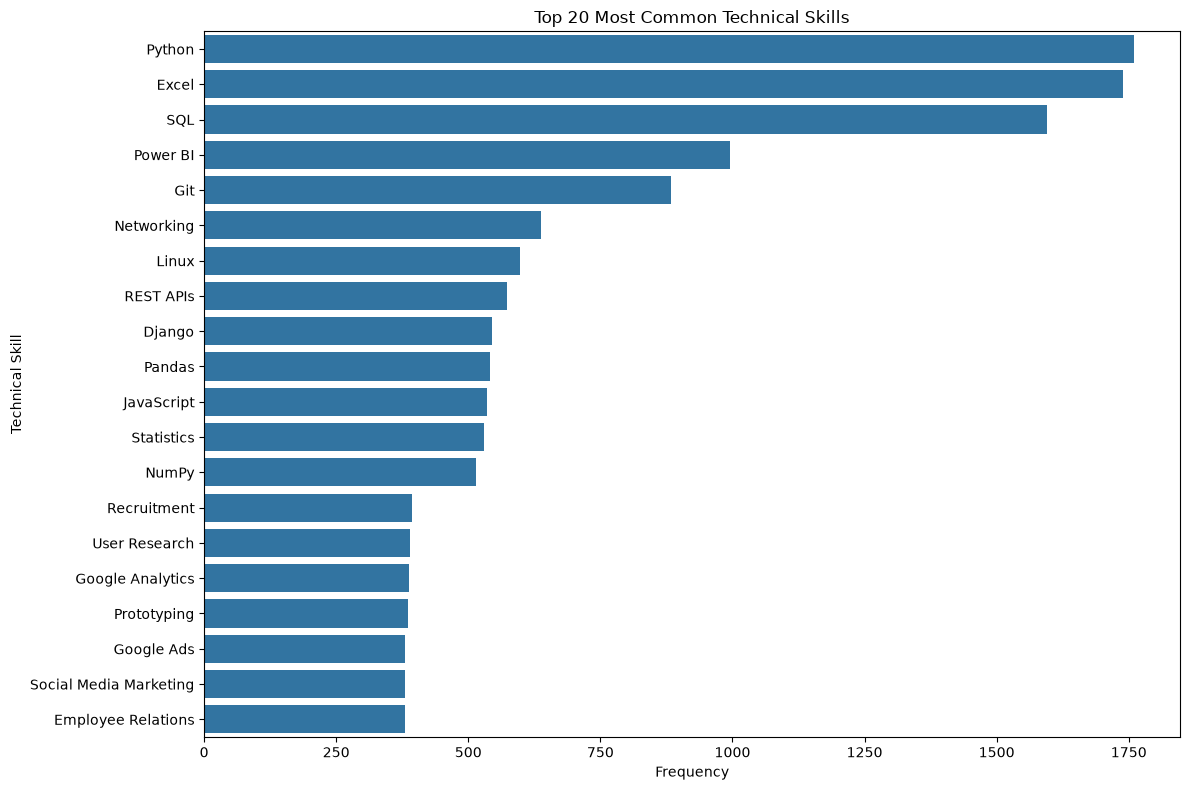

In [10]:
# Extract individual technical skills

from collections import Counter

technical_skill_list = (
    job_df["Technical_Skills_Parsed"]
    .dropna()
    .str.split(";")
)

technical_skills = [
    skill.strip()
    for skills in technical_skill_list
    for skill in skills
    if skill.strip()
]

technical_skill_counts = Counter(technical_skills)

technical_skill_df = pd.DataFrame(
    technical_skill_counts.most_common(20),
    columns=["Technical_Skill", "Record_Count"]
)

print("TOP 20 TECHNICAL SKILLS")
print("=" * 60)

display(technical_skill_df)

print("\nTotal unique individual technical skills:",
      len(technical_skill_counts))

# Visualize top 20 skills

plt.figure(figsize=(12, 8))

sns.barplot(
    data=technical_skill_df,
    x="Record_Count",
    y="Technical_Skill"
)

plt.title("Top 20 Most Common Technical Skills")
plt.xlabel("Frequency")
plt.ylabel("Technical Skill")
plt.tight_layout()
plt.show()

TOP 20 SOFT SKILLS


,Soft_Skill,Record_Count
0,Leadership,1858
1,Communication,1829
2,Critical Thinking,1824
3,Teamwork,1817
4,Collaboration,1813
5,Creativity,1806
6,Adaptability,1805
7,Problem Solving,1794
8,Time Management,1762
9,Decision Making,1755



Total unique individual soft skills: 10


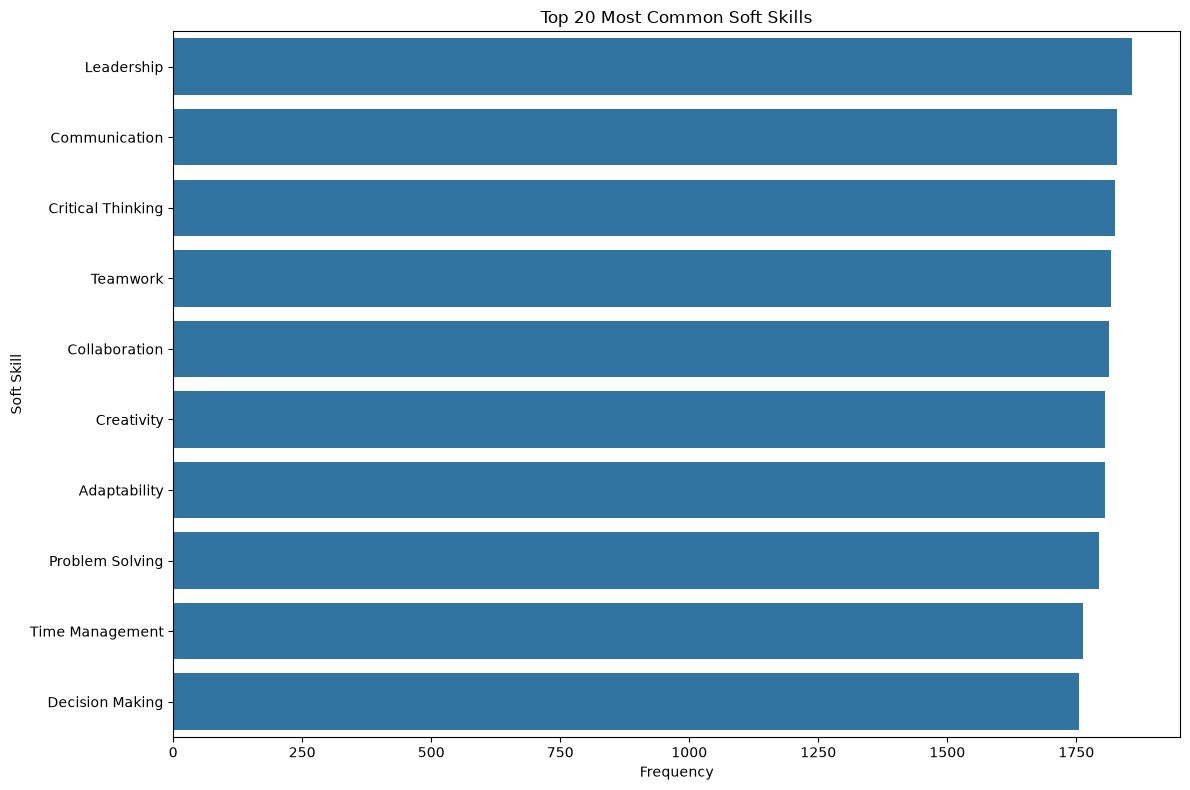

In [11]:
# Extract individual soft skills

from collections import Counter

soft_skill_list = (
    job_df["Soft_Skills_Parsed"]
    .dropna()
    .str.split(";")
)

soft_skills = [
    skill.strip()
    for skills in soft_skill_list
    for skill in skills
    if skill.strip()
]

soft_skill_counts = Counter(soft_skills)

soft_skill_df = pd.DataFrame(
    soft_skill_counts.most_common(20),
    columns=["Soft_Skill", "Record_Count"]
)

print("TOP 20 SOFT SKILLS")
print("=" * 60)

display(soft_skill_df)

print("\nTotal unique individual soft skills:",
      len(soft_skill_counts))

# Visualize top 20 soft skills

plt.figure(figsize=(12, 8))

sns.barplot(
    data=soft_skill_df,
    x="Record_Count",
    y="Soft_Skill"
)

plt.title("Top 20 Most Common Soft Skills")
plt.xlabel("Frequency")
plt.ylabel("Soft Skill")
plt.tight_layout()
plt.show()

CERTIFICATIONS DISTRIBUTION


,Record_Count
Certifications,
Software Testing Certificate,534
AWS Cloud Practitioner,520
Java Certification,509
Azure Fundamentals,502
Google UX Design,502
Digital Marketing Certificate,496
Google Data Analytics,493
Microsoft Power BI Data Analyst,493
HR Analytics Certificate,493



Total unique certification entries: 12


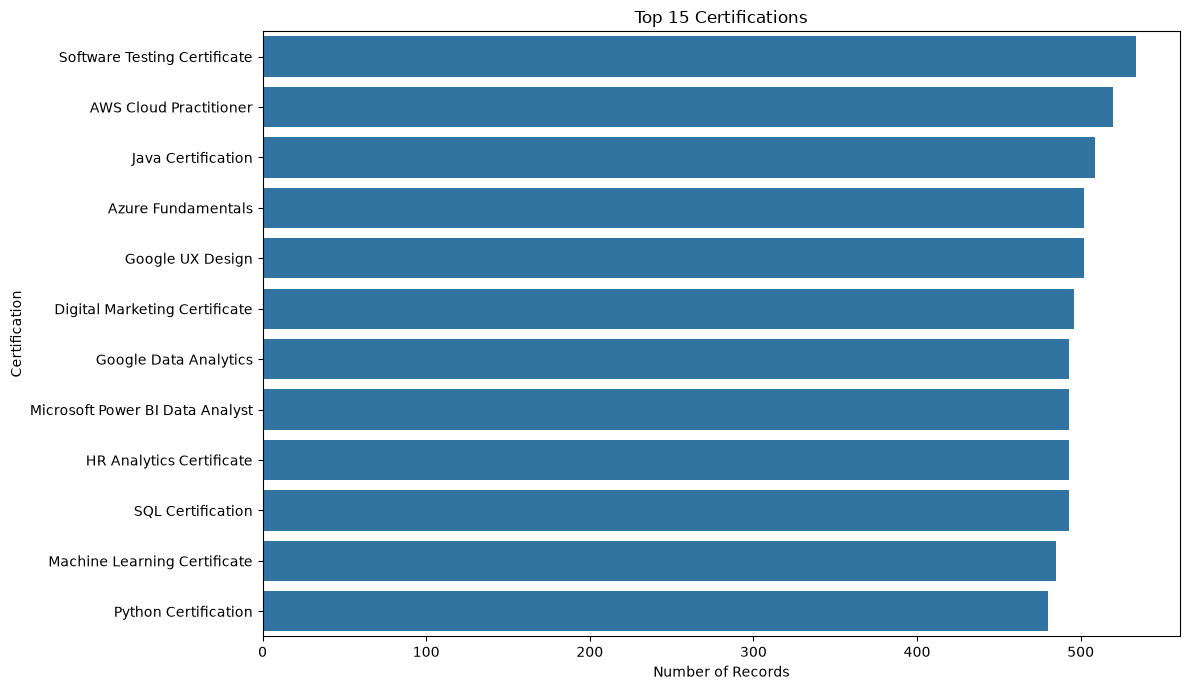

In [13]:
# Certifications distribution

print("CERTIFICATIONS DISTRIBUTION")
print("=" * 60)

certification_counts = job_df["Certifications"].value_counts()

display(
    certification_counts.head(20).to_frame(name="Record_Count")
)

print("\nTotal unique certification entries:",
      job_df["Certifications"].nunique())

# Visualize top 15 certifications

plt.figure(figsize=(12, 7))

sns.countplot(
    data=job_df,
    y="Certifications",
    order=certification_counts.head(15).index
)

plt.title("Top 15 Certifications")
plt.xlabel("Number of Records")
plt.ylabel("Certification")
plt.tight_layout()
plt.show()

EMPLOYMENT TYPE DISTRIBUTION


,Record_Count
Employment_Type_Interest,
Full-time,1246
Internship,1217
Contract,1202
Part-time,1186
Freelance,1149



Total employment types: 5


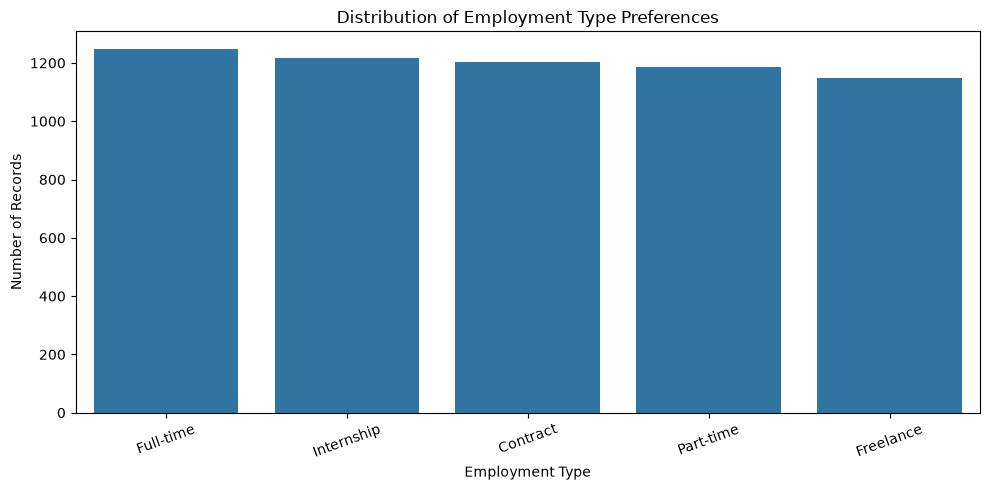

In [14]:
# Employment type distribution

print("EMPLOYMENT TYPE DISTRIBUTION")
print("=" * 60)

employment_counts = job_df["Employment_Type_Interest"].value_counts()

display(
    employment_counts.to_frame(name="Record_Count")
)

print("\nTotal employment types:",
      job_df["Employment_Type_Interest"].nunique())

# Visualize employment type distribution

plt.figure(figsize=(10, 5))

sns.barplot(
    x=employment_counts.index,
    y=employment_counts.values
)

plt.title("Distribution of Employment Type Preferences")
plt.xlabel("Employment Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

FIELDS OF INTEREST DISTRIBUTION


,Record_Count
Fields_of_Interest,
Cloud Computing,512
Human Resources,511
Digital Marketing,511
Web Development,510
UI/UX Design,509
Quality Assurance,506
Data Analytics,504
AI/ML,500
Finance,497



Total unique fields of interest: 12


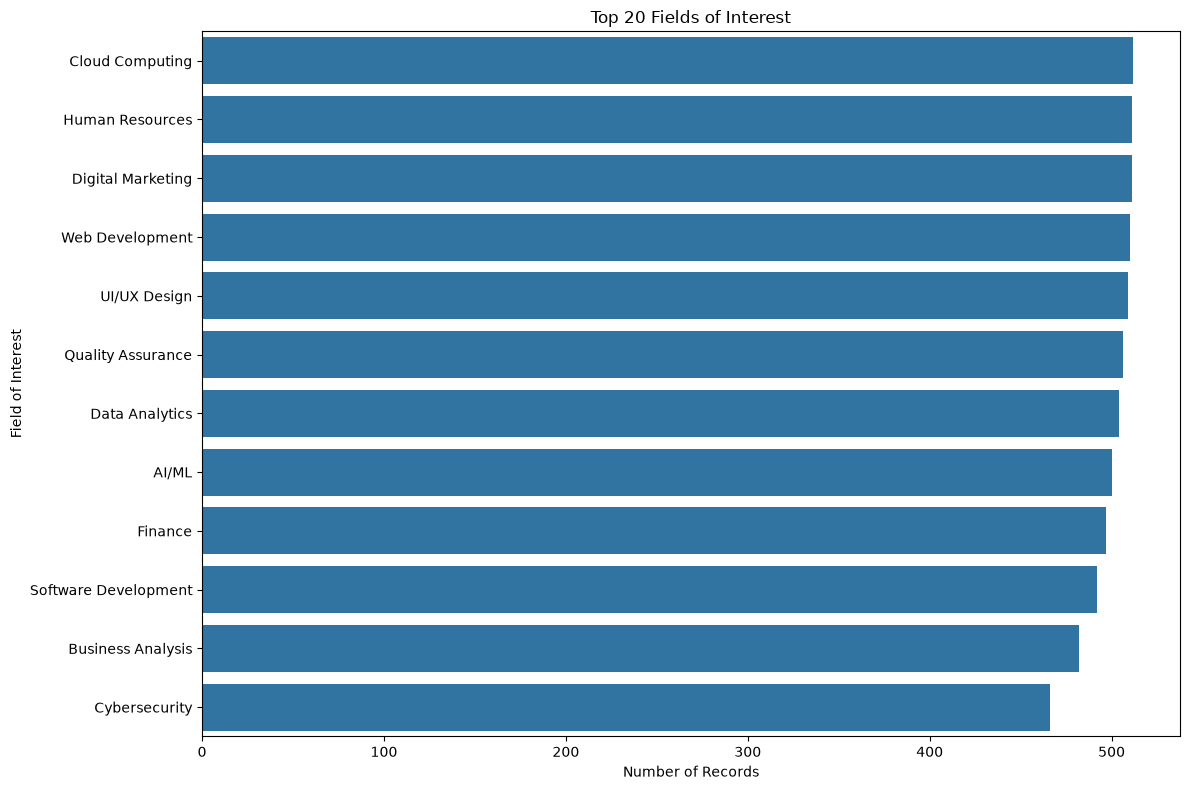

In [15]:
# Fields of interest distribution

print("FIELDS OF INTEREST DISTRIBUTION")
print("=" * 60)

interest_counts = job_df["Fields_of_Interest"].value_counts()

display(
    interest_counts.head(20).to_frame(name="Record_Count")
)

print("\nTotal unique fields of interest:",
      job_df["Fields_of_Interest"].nunique())

# Visualize top 20 fields

plt.figure(figsize=(12, 8))

sns.countplot(
    data=job_df,
    y="Fields_of_Interest",
    order=interest_counts.head(20).index
)

plt.title("Top 20 Fields of Interest")
plt.xlabel("Number of Records")
plt.ylabel("Field of Interest")
plt.tight_layout()
plt.show()

EXPECTED SALARY ANALYSIS
Salary statistics:


,Expected_Salary_INR_Annual
count,6000.000000
mean,433166.833333
std,87903.336111
min,220000.000000
25%,364000.000000
50%,500000.000000
75%,500000.000000
max,500000.000000



Salary values at ₹5,00,000:
3326

Salary values above ₹5,00,000:
0


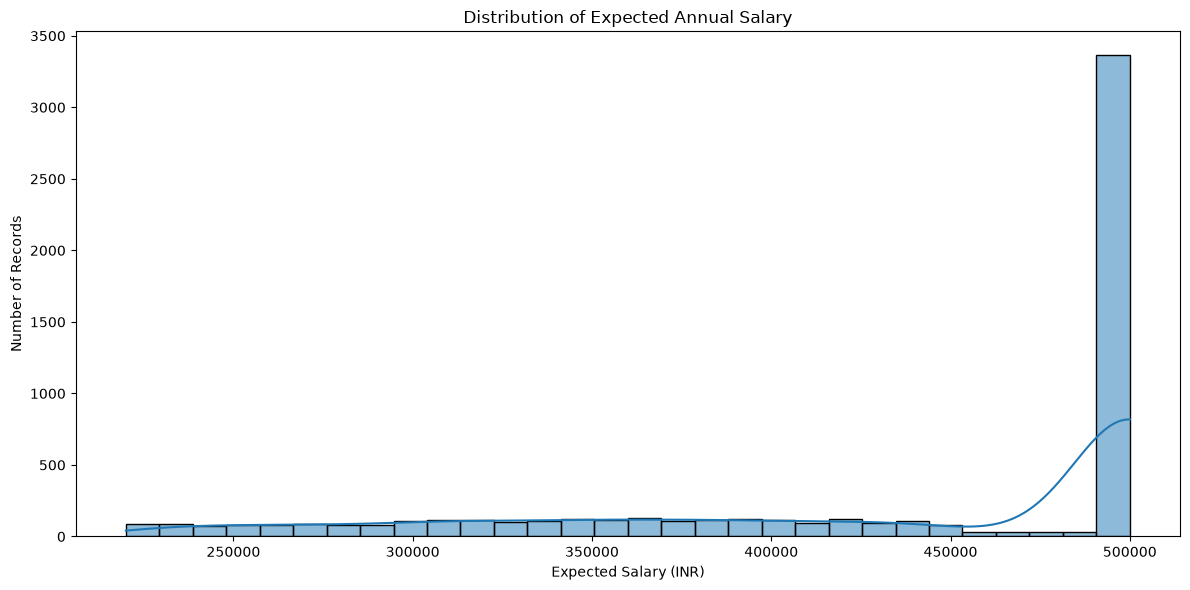

In [16]:
# Expected salary analysis

print("EXPECTED SALARY ANALYSIS")
print("=" * 60)

print("Salary statistics:")
display(
    job_df["Expected_Salary_INR_Annual"].describe().to_frame()
)

print("\nSalary values at ₹5,00,000:")
print(
    (job_df["Expected_Salary_INR_Annual"] == 500000).sum()
)

print("\nSalary values above ₹5,00,000:")
print(
    (job_df["Expected_Salary_INR_Annual"] > 500000).sum()
)

# Salary distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=job_df,
    x="Expected_Salary_INR_Annual",
    bins=30,
    kde=True
)

plt.title("Distribution of Expected Annual Salary")
plt.xlabel("Expected Salary (INR)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

EXPERIENCE VS RECOMMENDED JOB


Experience_Years,0,1,2,3,4,5,6,7,8,10
Recommended_Job,,,,,,,,,,
Business Analyst,0,0,59,45,29,39,0,0,0,0
Cloud Engineer,0,0,65,63,34,38,0,0,0,0
Cybersecurity Analyst,0,0,59,39,39,28,0,0,0,0
Data Analyst,0,0,62,54,33,41,0,0,0,0
Digital Marketing Associate,191,69,0,0,0,0,0,0,0,0
Digital Marketing Manager,0,0,0,0,0,0,23,18,17,18
Digital Marketing Specialist,0,0,54,41,46,34,0,0,0,0
Financial Analyst,0,0,38,49,39,30,0,0,0,0
HR / Recruitment Associate,164,82,0,0,0,0,0,0,0,0


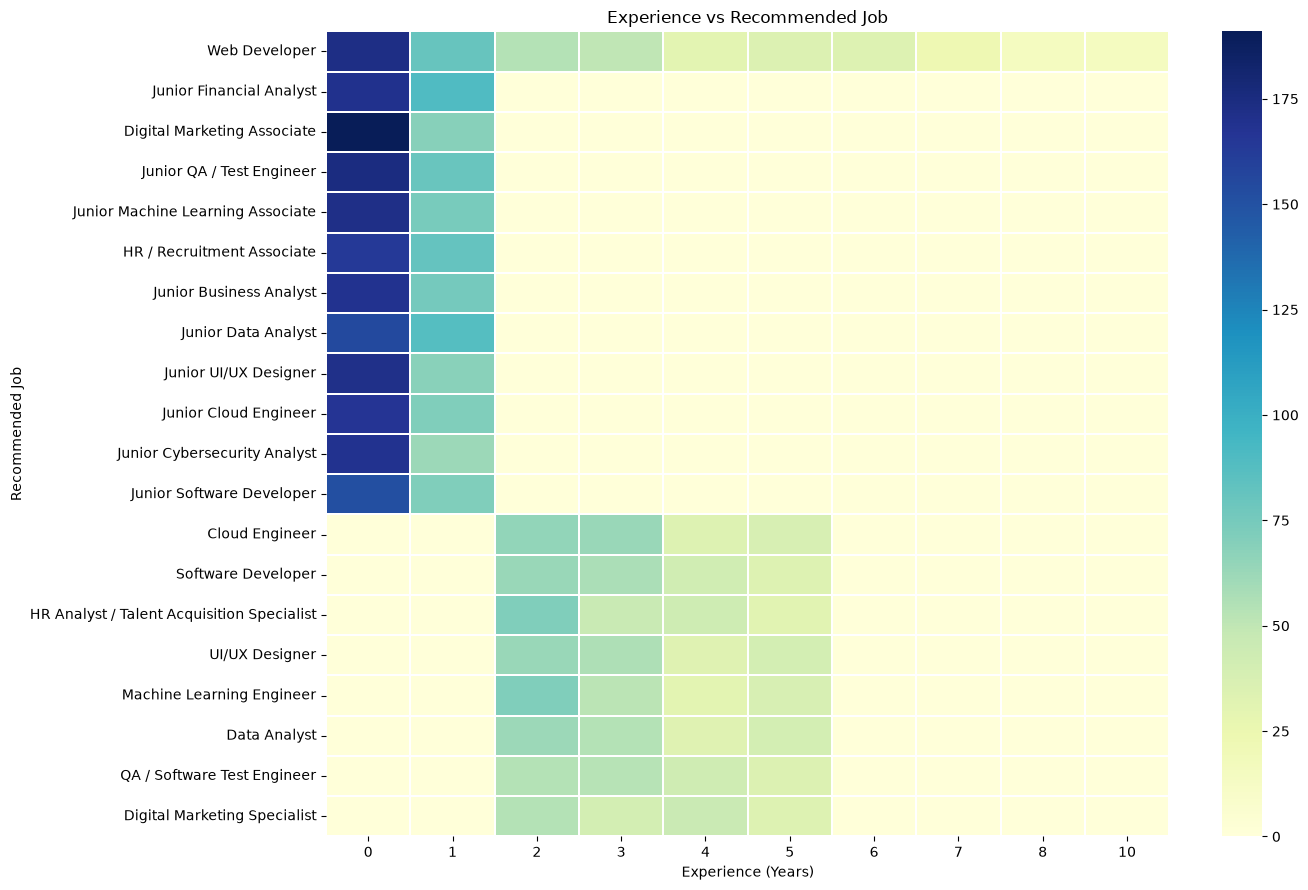

In [17]:
# Experience vs Recommended Job

print("EXPERIENCE VS RECOMMENDED JOB")
print("=" * 60)

experience_job = pd.crosstab(
    job_df["Recommended_Job"],
    job_df["Experience_Years"]
)

display(experience_job)

# Heatmap for top 20 jobs

top_jobs = job_df["Recommended_Job"].value_counts().head(20).index

plt.figure(figsize=(14, 9))

sns.heatmap(
    experience_job.loc[top_jobs],
    annot=False,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Experience vs Recommended Job")
plt.xlabel("Experience (Years)")
plt.ylabel("Recommended Job")
plt.tight_layout()
plt.show()

QUALIFICATION VS RECOMMENDED JOB


Highest_Qualification,B.Com,B.Sc,B.Tech,BA,BCA,BE,Diploma,M.Sc,M.Tech,MBA,MCA
Recommended_Job,,,,,,,,,,,
Business Analyst,12,14,12,19,17,16,17,14,13,19,19
Cloud Engineer,17,18,21,21,17,13,16,23,18,15,21
Cybersecurity Analyst,12,16,11,8,20,22,18,11,18,14,15
Data Analyst,15,15,15,19,20,20,14,22,20,17,13
Digital Marketing Associate,22,20,25,31,18,23,19,29,22,30,21
Digital Marketing Manager,8,11,8,10,3,5,8,8,5,5,5
Digital Marketing Specialist,16,13,21,15,12,17,18,17,18,12,16
Financial Analyst,15,13,17,20,16,19,8,15,11,7,15
HR / Recruitment Associate,18,20,27,20,27,20,19,22,25,16,32


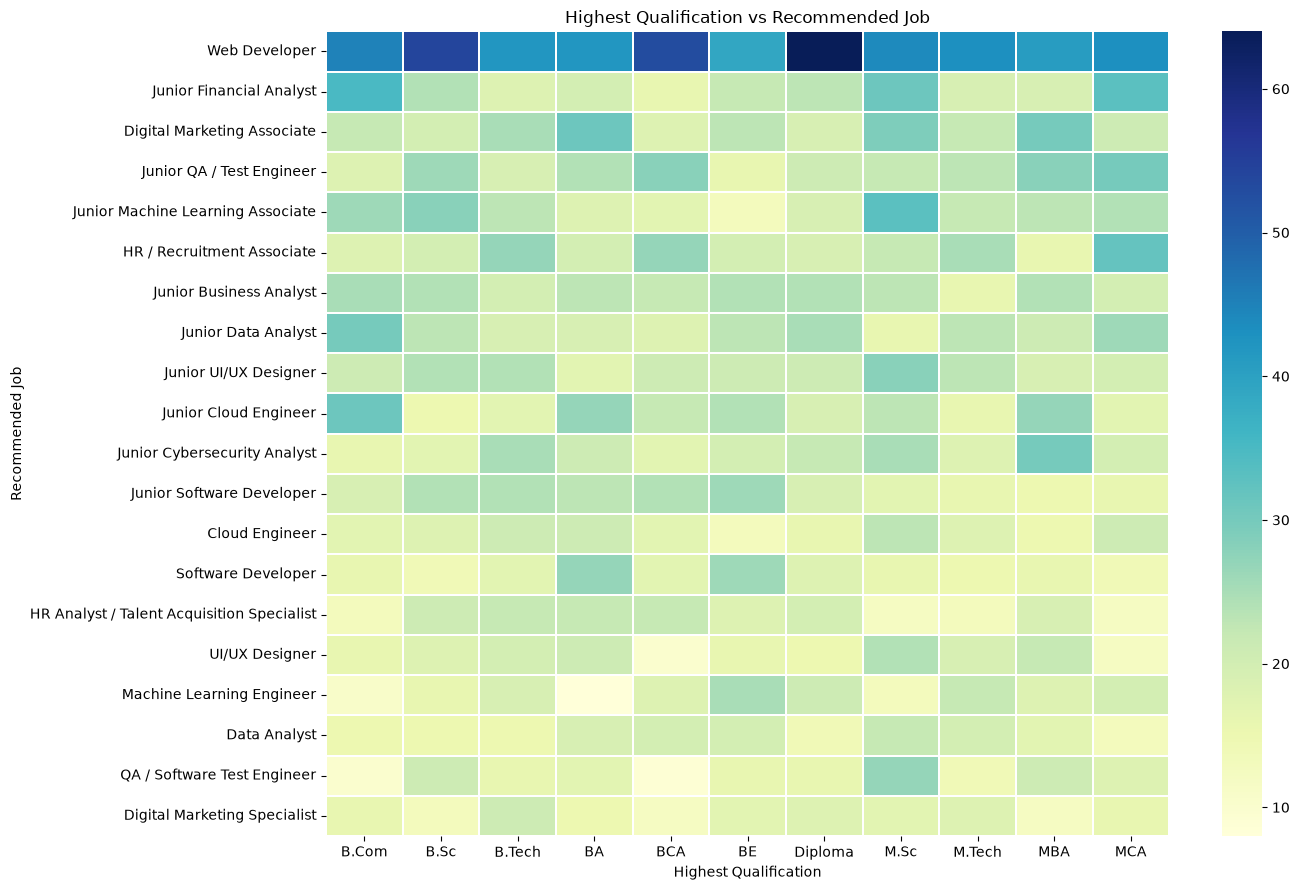

In [18]:
# Qualification vs Recommended Job

print("QUALIFICATION VS RECOMMENDED JOB")
print("=" * 60)

qualification_job = pd.crosstab(
    job_df["Recommended_Job"],
    job_df["Highest_Qualification"]
)

display(qualification_job)

# Visualize top 20 jobs

top_jobs = job_df["Recommended_Job"].value_counts().head(20).index

plt.figure(figsize=(14, 9))

sns.heatmap(
    qualification_job.loc[top_jobs],
    annot=False,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Highest Qualification vs Recommended Job")
plt.xlabel("Highest Qualification")
plt.ylabel("Recommended Job")
plt.tight_layout()
plt.show()

FIELDS OF INTEREST VS RECOMMENDED JOB


Fields_of_Interest,AI/ML,Business Analysis,Cloud Computing,Cybersecurity,Data Analytics,Digital Marketing,Finance,Human Resources,Quality Assurance,Software Development,UI/UX Design,Web Development
Recommended_Job,,,,,,,,,,,,
Business Analyst,0,172,0,0,0,0,0,0,0,0,0,0
Cloud Engineer,0,0,200,0,0,0,0,0,0,0,0,0
Cybersecurity Analyst,0,0,0,165,0,0,0,0,0,0,0,0
Data Analyst,0,0,0,0,190,0,0,0,0,0,0,0
Digital Marketing Associate,0,0,0,0,0,260,0,0,0,0,0,0
Digital Marketing Manager,0,0,0,0,0,76,0,0,0,0,0,0
Digital Marketing Specialist,0,0,0,0,0,175,0,0,0,0,0,0
Financial Analyst,0,0,0,0,0,0,156,0,0,0,0,0
HR / Recruitment Associate,0,0,0,0,0,0,0,246,0,0,0,0



Shape of cross-tabulation: (34, 12)


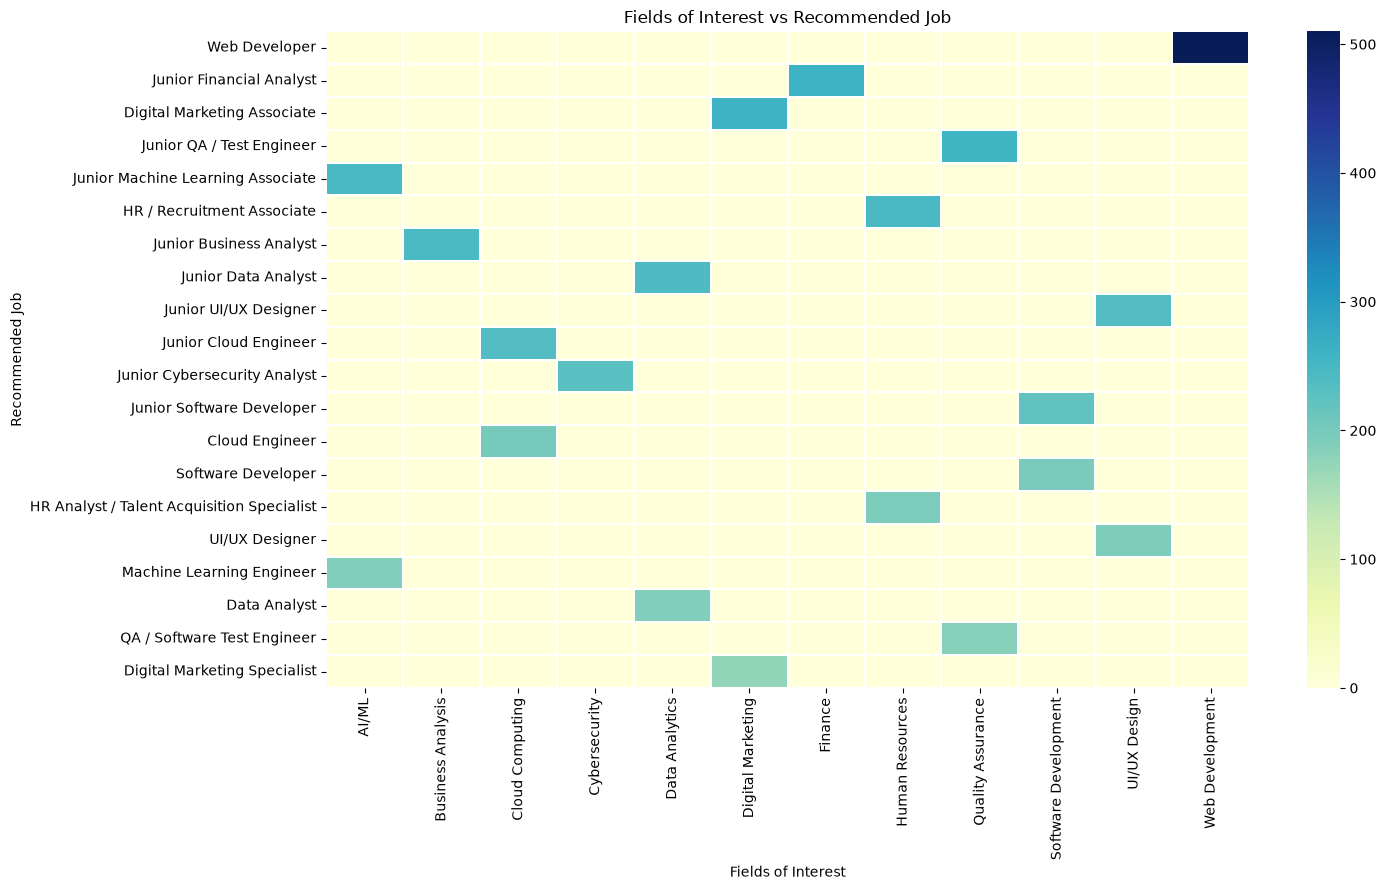

In [19]:
# Fields of Interest vs Recommended Job

print("FIELDS OF INTEREST VS RECOMMENDED JOB")
print("=" * 60)

interest_job = pd.crosstab(
    job_df["Recommended_Job"],
    job_df["Fields_of_Interest"]
)

display(interest_job)

print("\nShape of cross-tabulation:", interest_job.shape)

# Heatmap for top 20 recommended jobs

top_jobs = job_df["Recommended_Job"].value_counts().head(20).index

plt.figure(figsize=(15, 9))

sns.heatmap(
    interest_job.loc[top_jobs],
    annot=False,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Fields of Interest vs Recommended Job")
plt.xlabel("Fields of Interest")
plt.ylabel("Recommended Job")
plt.tight_layout()
plt.show()